In [105]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
from sklearn.utils.class_weight import compute_class_weight

In [106]:
# Set the dataset path and automatically identify the six class folders.
dataset_path = "dataset-resized"
classes = [
    item for item in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, item))
]

print(classes)
print(len(classes))
# Store every image path together with its corresponding class label
image_paths = []
labels = []

['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
6


In [107]:
# Loop through each class and collect all image paths and labels.
for i in classes:
    class_path = os.path.join(dataset_path, i)
    imgs = os.listdir(class_path)
    img_cnt = len(imgs)
    for i1 in range(img_cnt):
        image_nm = imgs[i1]
        image_path = os.path.join(class_path, image_nm)
        image_paths.append(image_path)
        labels.append(i)

print(image_paths[0], labels[0])
print(len(image_paths), len(labels))

dataset-resized\cardboard\cardboard1.jpg cardboard
2527 2527


In [ ]:
# Split the dataset into 70% training and 30% temporary data.
# Stratification keeps the class distribution balanced.
x_train, x_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size = 0.30,
    stratify = labels,
    random_state = 42
)

In [108]:
# Split the temporary data equally into validation and test sets
x_val, x_test, y_val, y_test = train_test_split(
    x_temp,
    y_temp,
    test_size = 0.50,
    stratify = y_temp,
    random_state = 42
)

In [109]:
# Check the number of samples in each class.
# This helps identify class imbalance.
print("training - ", len(x_train), len(y_train))
print("testing - ", len(x_test), len(y_test))
print("validation - ", len(x_val), len(y_val))

training -  1768 1768
testing -  380 380
validation -  379 379


In [110]:
print("training",Counter(y_train))
print("validation",Counter(y_val))
print("testing",Counter(y_test))

training Counter({'paper': 416, 'glass': 350, 'plastic': 337, 'metal': 287, 'cardboard': 282, 'trash': 96})
validation Counter({'paper': 89, 'glass': 75, 'plastic': 72, 'cardboard': 61, 'metal': 61, 'trash': 21})
testing Counter({'paper': 89, 'glass': 76, 'plastic': 73, 'metal': 62, 'cardboard': 60, 'trash': 20})


In [111]:
sample_path = x_train[0]


In [ ]:

# Check the original image dimensions before preprocessing.

In [112]:
sample_image = Image.open(sample_path)
print(sample_image.size)

(512, 384)


In [ ]:
# Resize images to 128x128 to create a fixed input size for the CNN.
image_resized = sample_image.resize((128,128))
print(image_resized.size)

(128, 128)


In [114]:
# Convert the image into a NumPy array for numerical processing.

arr_img = np.array(image_resized)
print(arr_img.shape)
print(arr_img.dtype)

(128, 128, 3)
uint8


In [115]:
print(arr_img[0,0])
print(arr_img.min())
print(arr_img.max())

[192 190 191]
0
255


In [116]:
# Normalize pixel values from 0-255 to 0-1.
arr_normalised = arr_img/255.0
print(arr_normalised.dtype)
print(arr_normalised.min())
print(arr_normalised.max())
print(arr_normalised[0,0])

float64
0.0
1.0
[0.75294118 0.74509804 0.74901961]


In [117]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

In [118]:
image_batch = tf.expand_dims(arr_img, axis = 0)
print(image_batch.shape)

(1, 128, 128, 3)


In [119]:
aug_img = data_augmentation(image_batch)
print(aug_img.shape)

(1, 128, 128, 3)


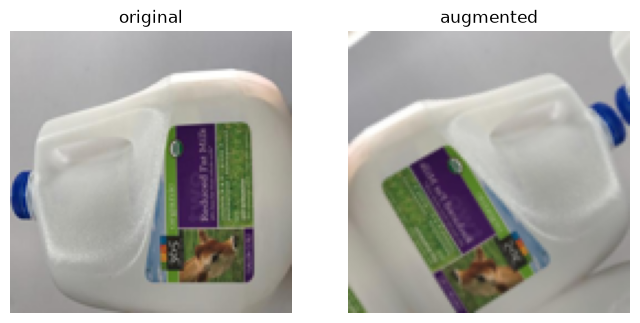

In [120]:
plt.figure(figsize = (8,4))

plt.subplot(1,2,1)
plt.imshow(arr_img)
plt.title("original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(aug_img[0].numpy().astype("uint8"))
plt.title("augmented")
plt.axis("off")

plt.show()

In [121]:
def augment(image, label):
    image = tf.expand_dims(image, axis=0)
    image = data_augmentation(image, training=True)
    image = tf.squeeze(image, axis=0)

    return image, label

In [123]:
label_to_index = {
    "cardboard": 0,
    "glass": 1,
    "metal": 2,
    "paper": 3,
    "plastic": 4,
    "trash": 5
}
y_train_encoded = [label_to_index[label] for label in y_train]
y_val_encoded = [label_to_index[label] for label in y_val]
y_test_encoded = [label_to_index[label] for label in y_test]
y_train_encoded = np.array(y_train_encoded)
y_val_encoded = np.array(y_val_encoded)
y_test_encoded = np.array(y_test_encoded)
print(y_train_encoded[:10])
print(y_val_encoded[:10])
print(y_test_encoded[:10])

[4 0 0 0 2 2 3 4 4 3]
[3 1 3 4 4 1 3 3 1 3]
[2 4 0 1 1 4 2 4 3 3]


In [124]:
print(np.unique(y_train_encoded))
print(y_train_encoded.shape)

[0 1 2 3 4 5]
(1768,)


In [125]:
# Image preprocessing
def load_and_preprocess(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (128, 128))
    image = image / 255.0
    return image, label


# Create TensorFlow datasets
train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train_encoded))
val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val_encoded))
test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test_encoded))


# Preprocess datasets
train_ds = train_ds.map(
    load_and_preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    load_and_preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    load_and_preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
)


# Augmentation — training data only
train_ds = train_ds.map(
    augment,
    num_parallel_calls=tf.data.AUTOTUNE
)


# Shuffle, batch and prefetch
train_ds = (
    train_ds
    .shuffle(len(x_train))
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = val_ds.batch(32).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.batch(32).prefetch(tf.data.AUTOTUNE)



In [126]:
for images, labels in train_ds.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Labels:", labels[:10])

Images shape: (32, 128, 128, 3)
Labels shape: (32,)
Labels: tf.Tensor([1 1 4 0 3 2 4 2 2 1], shape=(10,), dtype=int64)


In [127]:
# 1. CNN architecture function
def build_cnn():

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(128, 128, 3)),

        tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Flatten(),

        tf.keras.layers.Dense(64, activation="relu"),

        tf.keras.layers.Dense(6, activation="softmax")
    ])

    return model


# 2. Training function
def train_model(
    model,
    train_dataset,
    validation_dataset,
    class_weights=None,
    epochs=10
):

    model.compile(
        optimizer=tf.keras.optimizers.Adam(),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    history = model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=epochs,
        class_weight=class_weights
    )

    return history

def evaluate_model(model, test_dataset, classes):

    # 1. Test evaluation
    test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)

    print("\nTest Loss:", test_loss)
    print("Test Accuracy:", test_accuracy)

    # 2. Generate predictions
    y_true = []
    y_pred = []

    for images, labels in test_dataset:
        predictions = model.predict(images, verbose=0)
        predicted_classes = np.argmax(predictions, axis=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predicted_classes)

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # 3. Classification report
    print("\nClassification Report:")
    print(
        classification_report(
            y_true,
            y_pred,
            target_names=classes
        )
    )

    # 4. Confusion matrix
    cm = confusion_matrix(y_true, y_pred)

    print("Confusion Matrix:")
    print(cm)

    return test_loss, test_accuracy, y_true, y_pred, cm


In [128]:
# ============================================================
# Experiment 1 — Baseline CNN
# ============================================================

model_exp1 = build_cnn()

history_exp1 = train_model(
    model=model_exp1,
    train_dataset=train_ds,
    validation_dataset=val_ds,
    class_weights=None,
    epochs=10
)

exp1= evaluate_model(
    model_exp1,
    test_ds,
    classes
)

Epoch 1/10


c:\Users\YASHUB HAYAT\anaconda3\envs\waste-cv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


56/56 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - accuracy: 0.2477 - loss: 1.7026 - val_accuracy: 0.3615 - val_loss: 1.5419
Epoch 2/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - accuracy: 0.3784 - loss: 1.4928 - val_accuracy: 0.3958 - val_loss: 1.4555
Epoch 3/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 8s 120ms/step - accuracy: 0.4140 - loss: 1.4153 - val_accuracy: 0.3219 - val_loss: 1.8561
Epoch 4/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 117ms/step - accuracy: 0.4451 - loss: 1.3431 - val_accuracy: 0.4222 - val_loss: 1.3874
Epoch 5/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 115ms/step - accuracy: 0.4853 - loss: 1.2708 - val_accuracy: 0.5356 - val_loss: 1.2365
Epoch 6/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 117ms/step - accuracy: 0.5187 - loss: 1.2265 - val_accuracy: 0.4987 - val_loss: 1.4087
Epoch 7/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 117ms/step - accuracy: 0.5515 - loss: 1.1584 - val_accuracy: 0.4565 - val_loss: 1.5109
Epoch 8/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 113ms/step - accuracy: 0.5277 - loss: 1.1626 - val_accuracy: 0.5594 - val_

In [129]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train_encoded),
    y=y_train_encoded
)
class_weights_dict = dict(
    zip(np.unique(y_train_encoded), class_weights)
)

print(class_weights_dict)


{np.int64(0): np.float64(1.044917257683215), np.int64(1): np.float64(0.8419047619047619), np.int64(2): np.float64(1.0267131242740999), np.int64(3): np.float64(0.7083333333333334), np.int64(4): np.float64(0.874381800197824), np.int64(5): np.float64(3.0694444444444446)}


In [ ]:
# ============================================================
# Experiment 2 — Class Weights
# ============================================================

model_exp2 = build_cnn()

history_exp2 = train_model(
    model=model_exp2,
    train_dataset=train_ds,
    validation_dataset=val_ds,
    class_weights=class_weights,
    epochs=10
)

exp2 = evaluate_model(
    model_exp2,
    test_ds,
    classes
)

[0.3235294222831726,
 0.4326923191547394,
 0.4937782883644104,
 0.554864227771759,
 0.5752262473106384,
 0.622171938419342,
 0.6380090713500977,
 0.6266968250274658,
 0.6555429697036743,
 0.6713801026344299]

In [ ]:
# Custom class weights
class_weights_custom = {
    0: 1.0449,
    1: 0.8419,
    2: 1.0267,
    3: 0.7083,
    4: 0.8744,
    5: 2.0
}


# Strong augmentation
data_augmentation_strong = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomContrast(0.15)
])


def augment_strong(image, label):
    image = tf.expand_dims(image, axis=0)
    image = data_augmentation_strong(image, training=True)
    image = tf.squeeze(image, axis=0)
    return image, label


# Create strongly augmented training dataset
train_ds_strong = tf.data.Dataset.from_tensor_slices(
    (x_train, y_train_encoded)
)

train_ds_strong = (
    train_ds_strong
    .map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .map(augment_strong, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(len(x_train))
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

In [ ]:
# ============================================================
# Experiment 3 — Custom Class Weights + Strong Augmentation
# ============================================================

model_exp3 = build_cnn()

history_exp3 = train_model(
    model=model_exp3,
    train_dataset=train_ds_strong,
    validation_dataset=val_ds,
    class_weights=class_weights_custom,
    epochs=10
)

exp3 = evaluate_model(
    model_exp3,
    test_ds,
    classes
)

In [ ]:
# ============================================================
# Experiment 4 — Global Average Pooling + Dropout
# ============================================================

model_exp4 = build_cnn(
    regularization=True
)

history_exp4 = train_model(
    model=model_exp4,
    train_dataset=train_ds,
    validation_dataset=val_ds,
    class_weights=class_weights_custom,
    epochs=10
)

exp4 = evaluate_model(
    model_exp4,
    test_ds,
    classes
)

In [ ]:
# ============================================================
# Experiment 5 — Additional Conv2D(256) Layer
# ============================================================

model_exp5 = build_cnn(
    extra_conv=True
)

history_exp5 = train_model(
    model=model_exp5,
    train_dataset=train_ds_strong,
    validation_dataset=val_ds,
    class_weights=class_weights_custom,
    epochs=10
)

exp5 = evaluate_model(
    model_exp5,
    test_ds,
    classes
)